# ab-data-quality: walkthrough

Everything in the repo, end to end:

1. [Validate one experiment](#1.-Validate-one-experiment): the step-by-step pipeline on a single experiment.
2. [One scenario per defect](#2.-One-scenario-per-defect): does each defect get the right status?
3. [Validate the assignment machinery](#3.-Validate-the-assignment-machinery): hashing checks, plus an A/A replay as a bridge to level 3.
4. [Simulation (a): selective exposure loss](#4.-Simulation-(a):-selective-exposure-loss): who notices first, SRM or a fake effect?
5. [Simulation (b): SRM monitoring](#5.-Simulation-(b):-your-SRM-check-is-peeking-too): your SRM check is peeking too.
6. [Validate the validator](#6.-Validate-the-validator): the pipeline's own error rates.

Figures go to `figures/`, tables to `results/`. Sections 4-6 are Monte Carlo and take a few minutes; the run time of each is noted in its section.

In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

from abdq import validate_experiment
from abdq import simulate as sim
from abdq.platform import (
    aa_replay, assign_variants, check_hash_determinism, check_hash_independence,
    check_hash_uniformity, event_level_ttest, unit_level_ttest,
)
from abdq.stats import log_mixture_srm

FIGURES, RESULTS = Path("figures"), Path("results")
FIGURES.mkdir(exist_ok=True)
(RESULTS / "reports").mkdir(parents=True, exist_ok=True)

# plot style: light surface, thin marks, recessive axes
SURFACE, TEXT, TEXT_2, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#8a8984"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "axes.titlecolor": TEXT,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "legend.frameon": False,
    "legend.labelcolor": TEXT, "lines.linewidth": 2.0, "figure.dpi": 110,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

## 1. Validate one experiment

The pipeline takes three event tables (assignments, exposures, outcomes) plus optional covariates, identities and reference counts. Here: a synthetic experiment with 40,000 users, where 5% of treatment exposures on iOS are never logged.

In [2]:
data, config = sim.generate_experiment(sim.SimSpec(n_units=40_000, seed=0))
broken = sim.inject_exposure_loss(data, rate=0.05, variant="treatment", segment=("platform", "ios"))

report = validate_experiment(broken, config)
print(report.status.value, report.reasons)
display(Markdown(report.to_markdown()))

untrustworthy ['3.4 exposure_rate_by_variant', '3.6 critical_segment[platform]']


## Experiment status: **UNTRUSTWORTHY**

Action: block the result until the root cause is found.

Blocking checks: 3.4 exposure_rate_by_variant, 3.6 critical_segment[platform].

| Step | Check | Kind | Result | Details |
|---|---|---|---|---|
| 1.1 | null_keys | confirmatory | PASS | Rows with null keys (worst table): 0.0000%. Dropped before further checks. |
| 1.2 | duplicates | diagnostic | PASS | Duplicate assignment rows: 0; duplicate outcome event_ids: 0. Removed. Duplicates inflate sums and variances; if they are concentrated in one variant, investigate the pipeline. |
| 1.3 | unknown_variants | confirmatory | PASS | All assigned variants are in the design. |
| 1.4 | timestamp_order | confirmatory | PASS | Outcome events processed before they happened: 0.0000%. |
| 2.1 | srm_assignment | confirmatory | PASS | SRM on assigned units: observed shares control=0.5013, treatment=0.4987; p = 6.03e-01 (ok under chi-square p < 0.001). |
| 2.2 | crossover_units | confirmatory | PASS | Units assigned to more than one variant: 0 (0.0000%). Usually an unstable unit id (re-hashed after login, new device) or a salt change mid-test. |
| 2.3 | assignment_window | diagnostic | PASS | Units assigned before the window: 0; after the window: 0. |
| 3.1 | orphan_exposures | confirmatory | PASS | Exposures with no matching assignment: 0 (0.0000%). Typically an id that changes between the assignment service and the client. |
| 3.2 | variant_mismatch | confirmatory | PASS | Exposures logged with a different variant than assigned: 0 (0.0000%). |
| 3.3 | exposure_before_assignment | confirmatory | PASS | Exposures timestamped before the unit was assigned: 0 (0.0000%). |
| 3.4 | exposure_rate_by_variant | confirmatory | FAIL | Exposed / assigned by variant: control=0.7028, treatment=0.6838; p = 3.62e-05. Unless the treatment itself changes who reaches the exposure point, these rates should match. |
| 3.5 | srm_exposed | confirmatory | PASS | SRM on exposed units: observed shares control=0.5082, treatment=0.4918; p = 6.52e-03 (ok under chi-square p < 0.001). |
| 3.6 | critical_segment[platform] | confirmatory | FAIL | Exposure rate differs between variants within platform = ['ios'] (Bonferroni alpha 3.3e-04). Loss concentrated in one segment is far easier to see here than in the overall SRM. |
| 4.1 | orphan_outcomes | confirmatory | PASS | Outcome events from units with no assignment: 0 (0.0000%). Usually an id mismatch between the event pipeline and the assignment service. |
| 4.2 | maturity | confirmatory | PASS | Buffer 3 days 00:00:00 covers the max expected lag 2 days 00:00:00. |
| 4.3 | lag_asymmetry | diagnostic | PASS | Lag distributions are similar across variants. |
| 4.4 | completeness_vs_reference | confirmatory | PASS | Outcome counts match the reference in every variant. |
| 5.1 | ids_per_unit | confirmatory | PASS | Mean device ids per unit by variant: {'control': 1.205, 'treatment': 1.212}; p = 9.24e-02. |
| 5.2 | shared_ids_across_variants | confirmatory | PASS | Device ids linked to units in different variants: 0 (0.0000%). The same physical device sees both experiences. |
| 6.1 | covariate_balance | confirmatory | PASS | Pre-period covariates balanced (2 covariates, Bonferroni alpha 5.0e-04). |
| 7 | segment[platform] | diagnostic | WARN | Levels of platform with SRM or exposure-rate imbalance: ['ios']. |

The overall SRM on exposed units passes (p ≈ 0.007, above the 0.001 threshold). The exposure rate by variant (3.4) and the per-platform check (3.6) catch it, and the diagnostic segment breakdown (step 7) points at iOS.

## 2. One scenario per defect

Each scenario breaks exactly one layer, so the right answer is known.

In [3]:
rows = []
for name, defect, expected, d, c in sim.defect_scenarios(seed=0):
    r = validate_experiment(d, c)
    (RESULTS / "reports" / f"{name}.md").write_text(
        f"# Scenario: {name}\n\nInjected defect: {defect}.\n\n" + r.to_markdown() + "\n")
    rows.append({"scenario": name, "injected defect": defect, "expected": expected,
                 "status": r.status.value, "blocking checks": "; ".join(r.reasons)})
scenarios = pd.DataFrame(rows)
scenarios.to_csv(RESULTS / "scenarios.csv", index=False)
scenarios

,scenario,injected defect,expected,status,blocking checks
0,healthy,none,trustworthy,trustworthy,
1,srm,assignment split 51/49 instead of 50/50,untrustworthy,untrustworthy,2.1 srm_assignment; 3.5 srm_exposed
2,crossover,1% of units also assigned to the other variant,untrustworthy,untrustworthy,2.2 crossover_units
3,exposure_loss_ios,5% of treatment exposures on iOS not logged,untrustworthy,untrustworthy,3.4 exposure_rate_by_variant; 3.6 critical_seg...
4,late_outcomes,"slow pipeline, data pulled 6h after the window",preliminary,preliminary,4.2 maturity; 4.4 completeness_vs_reference
5,outcome_loss,5% of treatment outcome events lost for good,untrustworthy,untrustworthy,4.4 completeness_vs_reference
6,identity_split,10% of treatment users get an extra device id,untrustworthy,untrustworthy,5.1 ids_per_unit
7,covariate_imbalance,"heavy users leak into treatment, counts stay 5...",untrustworthy,untrustworthy,6.1 covariate_balance


## 3. Validate the assignment machinery

Per-experiment checks assume the assignment machinery underneath is sound. These checks validate it, once and after every change to it.

**Hashing.** Three assignment functions: the reference sha256 implementation, a classic modulo-bias bug (two hex digits mod 100, so buckets 0-55 get three hashes and 56-99 get two), and a "global salt" bug where every experiment splits users identically. Each bug slips past at least one check, which is why there are three.

In [4]:
SPLIT = {"control": 0.5, "treatment": 0.5}

def good(ids, salt):
    return assign_variants(ids, salt, SPLIT)

def modulo_bias(ids, salt):
    b = np.array([int(hashlib.md5(f"{salt}:{u}".encode()).hexdigest()[:2], 16) % 100 for u in ids])
    return np.where(b < 50, "control", "treatment")

def global_salt(ids, salt):
    return assign_variants(ids, "global", SPLIT)

rows = []
for name, fn in [("sha256 reference", good), ("modulo bias bug", modulo_bias), ("global salt bug", global_salt)]:
    for check in (check_hash_uniformity(fn, SPLIT, n_ids=300_000),
                  check_hash_determinism(fn, n_ids=50_000),
                  check_hash_independence(fn, SPLIT, n_ids=200_000)):
        rows.append({"assignment": name, "check": check.name, "status": check.status.value,
                     "message": check.message})
hash_checks = pd.DataFrame(rows)
hash_checks.to_csv(RESULTS / "platform_hash_checks.csv", index=False)
hash_checks.pivot(index="assignment", columns="check", values="status")

check,hash_determinism,hash_independence,hash_uniformity
assignment,,,
global salt bug,pass,fail,pass
modulo bias bug,pass,pass,fail
sha256 reference,pass,pass,pass


### Bridge to level 3: A/A replay of the analysis code

This one is not a level-1 check. Random splits of historical data never touch the assignment service or the logging, so it validates only the *analysis code*: whether its p-values are calibrated. That's level 3 (metrics) of the hierarchy, and it's here because the tool lives in `abdq.platform`. A single live A/A test is one draw from the null; to check calibration, replay hundreds of random splits through the real analysis code. Two analyses of the same session-level data: aggregate to the randomization unit first (correct), or treat every session as independent (pseudoreplication).

PASS aa_replay_unit_level - 500 A/A replays: false positive rate 5.4% (expected 5%, 99% band 2.6%-7.6%); KS uniformity p = 2.58e-01.
FAIL aa_replay_event_level - 500 A/A replays: false positive rate 41.6% (expected 5%, 99% band 2.6%-7.6%); KS uniformity p = 4.37e-75. The analysis pipeline is miscalibrated.


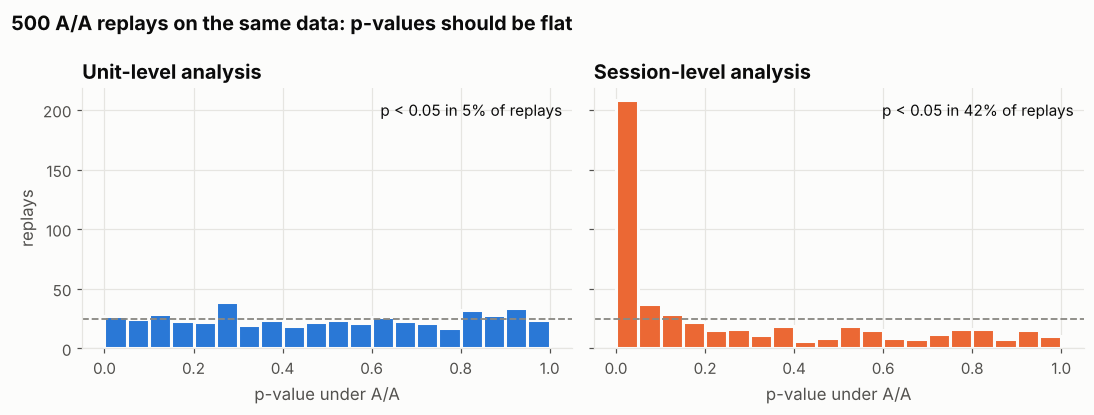

In [5]:
def historical_sessions(n_users=4_000, seed=0):
    rng = np.random.default_rng(seed)
    user_level = rng.lognormal(1.0, 1.0, size=n_users)
    sessions = 1 + rng.poisson(6, size=n_users)
    uid = np.repeat(np.arange(n_users), sessions)
    return pd.DataFrame({"unit_id": uid, "value": user_level[uid] * rng.lognormal(0, 0.5, size=len(uid))})

events = historical_sessions()
res_unit = aa_replay(events, unit_level_ttest, n_replays=500, name="aa_replay_unit_level")
res_event = aa_replay(events, event_level_ttest, n_replays=500, name="aa_replay_event_level")
for r in (res_unit, res_event):
    print(r.check.status.value.upper(), r.check.name, "-", r.check.message)
pd.DataFrame([
    {"analysis": "unit-level t-test", "fpr": res_unit.false_positive_rate, "ks_p_value": res_unit.ks_p_value},
    {"analysis": "event-level t-test", "fpr": res_event.false_positive_rate, "ks_p_value": res_event.ks_p_value},
]).to_csv(RESULTS / "platform_aa_replay.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, r, title, color in [(axes[0], res_unit, "Unit-level analysis", SERIES[0]),
                            (axes[1], res_event, "Session-level analysis", SERIES[1])]:
    ax.hist(r.p_values, bins=bins, color=color, edgecolor=SURFACE, linewidth=2)
    ax.axhline(len(r.p_values) / 20, color=NEUTRAL, linestyle="--", linewidth=1.2)
    ax.set_title(title)
    ax.set_xlabel("p-value under A/A")
    ax.text(0.98, 0.95, f"p < 0.05 in {r.false_positive_rate:.0%} of replays",
            transform=ax.transAxes, ha="right", va="top", color=TEXT, fontsize=10)
axes[0].set_ylabel("replays")
fig.suptitle("500 A/A replays on the same data: p-values should be flat",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXT)
fig.tight_layout()
fig.savefig(FIGURES / "aa_replay_pvalues.png")
plt.show()

## 4. Simulation (a): selective exposure loss

Assignment is perfect, 50/50. In treatment, 1% of exposures are never logged, and the analysis runs on logged units, as most dashboards do. There is no true effect. Two tests race as the experiment grows: the SRM check on logged units (p < 0.001) and the A/B test itself (p < 0.05), where every rejection is a fake effect caused by the loss.

With `m` assigned units per arm (before the loss), the normal approximation gives

$$z_{\text{SRM}} \approx L\sqrt{m/2}, \qquad z_{\text{test}} \approx d \cdot L\sqrt{m/2}, \qquad d = \frac{\bar y_{\text{all}} - \bar y_{\text{lost}}}{\sigma_y}.$$

Both grow like $\sqrt m$, so sample size doesn't decide the race; $|d|$ does. The A/B test crosses 1.96 when $z_{\text{SRM}} = 1.96/|d|$, while SRM needs 3.29. Once $|d| > 1.96/3.29 \approx 0.6$, a fake effect is more likely than not before SRM is more likely than not to fire.

Revenue per user ~ LogNormal(0, 1). The lost units come from different parts of the distribution. Run time ≈ 30 s.

In [6]:
LOSS, SIGMA, SRM_ALPHA, TEST_ALPHA = 0.01, 1.0, 1e-3, 0.05
M_GRID_MC, RUNS = [3_000, 10_000, 30_000, 100_000, 300_000], 200
MECHANISMS = {
    "random loss": lambda q: np.full_like(q, LOSS),
    "lost among top 20% spenders": lambda q: np.where(q > 0.80, LOSS / 0.20, 0.0),
    "lost among top 2% spenders": lambda q: np.where(q > 0.98, LOSS / 0.02, 0.0),
}

def mechanism_d(fn, n=2_000_000, seed=0):
    rng = np.random.default_rng(seed)
    y = rng.lognormal(0, SIGMA, size=n)
    w = fn(stats.rankdata(y) / n)
    return abs(float((y.mean() - (w * y).sum() / w.sum()) / y.std()))

def power(z, crit):
    return stats.norm.cdf(np.abs(z) - crit) + stats.norm.cdf(-np.abs(z) - crit)

def monte_carlo(fn, m, runs, rng):
    srm_hits = fp_hits = 0
    for _ in range(runs):
        mt = int(rng.binomial(2 * m, 0.5))            # assignment itself is random
        yc = rng.lognormal(0, SIGMA, size=2 * m - mt)
        yt = rng.lognormal(0, SIGMA, size=mt)
        keep = rng.random(mt) >= fn(stats.lognorm.cdf(yt, s=SIGMA))
        counts = np.array([len(yc), keep.sum()], dtype=float)
        exp = counts.sum() / 2
        srm_hits += stats.chi2.sf(((counts - exp) ** 2 / exp).sum(), df=1) < SRM_ALPHA
        fp_hits += stats.ttest_ind(yt[keep], yc, equal_var=False).pvalue < TEST_ALPHA
    return srm_hits / runs, fp_hits / runs

rng = np.random.default_rng(20261016)
d_values = {name: mechanism_d(fn) for name, fn in MECHANISMS.items()}
rows = []
for name, fn in MECHANISMS.items():
    for m in M_GRID_MC:
        srm_mc, fp_mc = monte_carlo(fn, m, RUNS, rng)
        rows.append({"mechanism": name, "d": d_values[name], "units_per_arm": m,
                     "srm_detection_mc": srm_mc, "false_positive_mc": fp_mc})
mc = pd.DataFrame(rows)
mc.to_csv(RESULTS / "sim_exposure_loss_mc.csv", index=False)
mc.pivot(index="units_per_arm", columns="mechanism", values=["false_positive_mc", "srm_detection_mc"]).round(3)

false_positive_mc                              \
mechanism     lost among top 2% spenders lost among top 20% spenders   
units_per_arm                                                          
3000                               0.585                       0.100   
10000                              0.955                       0.155   
30000                              1.000                       0.465   
100000                             1.000                       0.905   
300000                             1.000                       1.000   

                                    srm_detection_mc  \
mechanism     random loss lost among top 2% spenders   
units_per_arm                                          
3000                0.050                      0.000   
10000               0.085                      0.010   
30000               0.050                      0.015   
100000              0.050                      0.170   
300000              0.080                      0.705   

                                                       
mechanism     lost among top 20% spenders random loss  
units_per_arm                                          
3000                                0.000       0.005  
10000                               0.005       0.000  
30000                               0.010       0.025  
100000                              0.145       0.160  
300000                              0.695       0.730

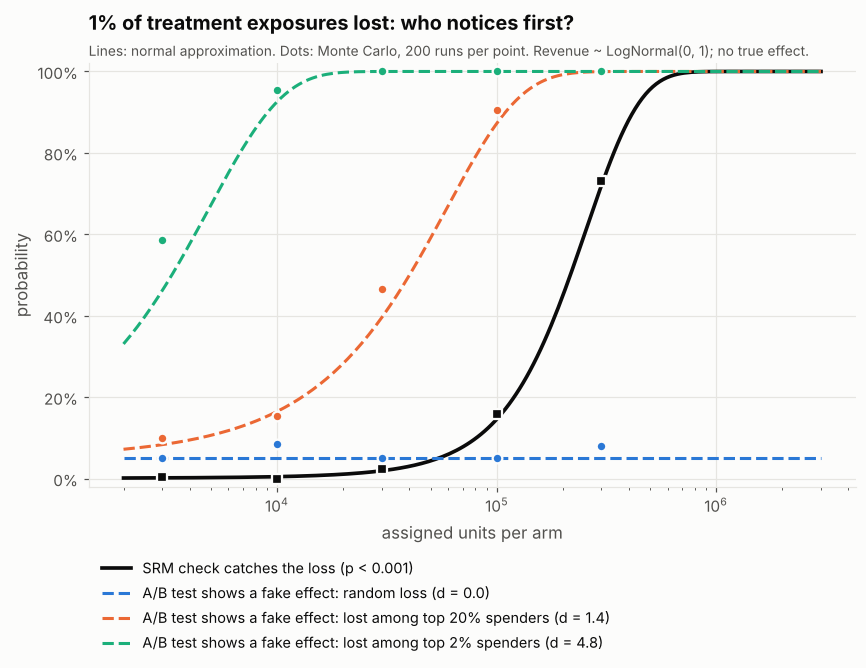

In [7]:
m_curve = np.logspace(np.log10(2_000), np.log10(3_000_000), 200)
z_srm = LOSS * np.sqrt(m_curve / 2)
srm_detect = power(z_srm, stats.norm.isf(SRM_ALPHA / 2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(m_curve, srm_detect, color=TEXT, linewidth=2.4, label="SRM check catches the loss (p < 0.001)")
for (name, d), color in zip(d_values.items(), SERIES):
    ax.plot(m_curve, power(d * z_srm, stats.norm.isf(TEST_ALPHA / 2)), color=color, linestyle="--",
            label=f"A/B test shows a fake effect: {name} (d = {d:.1f})")
    sub = mc[mc["mechanism"] == name]
    ax.scatter(sub["units_per_arm"], sub["false_positive_mc"], color=color, s=40,
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
sub = mc[mc["mechanism"] == "random loss"]
ax.scatter(sub["units_per_arm"], sub["srm_detection_mc"], color=TEXT, s=40,
           edgecolor=SURFACE, linewidth=1.5, zorder=3, marker="s")
ax.set_xscale("log")
ax.set_ylim(-0.02, 1.02)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("assigned units per arm")
ax.set_ylabel("probability")
ax.set_title("1% of treatment exposures lost: who notices first?", pad=22)
ax.text(0, 1.01, "Lines: normal approximation. Dots: Monte Carlo, 200 runs per point. "
        "Revenue ~ LogNormal(0, 1); no true effect.",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=9, color=TEXT_2)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), fontsize=9.5)
fig.savefig(FIGURES / "exposure_loss_race.png")
plt.show()

When the loss hits the top 2% of spenders ($d \approx 4.8$), the A/B test shows a significant fake effect in almost every run at 10k users per arm, while SRM catches the loss in about 1%. The practical answer: check the layers directly (exposure rate by variant and within critical segments), and where possible analyze by assignment rather than by logged exposure.

## 5. Simulation (b): your SRM check is peeking too

Platforms recompute SRM every day or every hour. That is repeated testing. A 14-day test with ~12,200 users per day, sized so that a single chi-square check at the end (p < 0.001) has the textbook 80% power against a 49.5/50.5 split. 20,000 simulated tests per rule:

- chi-square at p < 0.05 or p < 0.001, checked daily or hourly, or once at the end;
- the anytime-valid Dirichlet-multinomial mixture likelihood ratio (Lindon & Malek, 2022), checked hourly, at nominal α = 0.001;
- the same mixture with its threshold **calibrated** by simulation to the realized false alarm rate of daily chi-square at p < 0.001. Ville's inequality is conservative, so equal nominal α is an unfair comparison. The catch: the calibrated threshold is only guaranteed for the traffic, horizon and look schedule it was calibrated on.

Run time ≈ 1 min.

In [8]:
DAYS, HOURS, RUNS_B, CONCENTRATION = 14, 14 * 24, 20_000, 10_000.0

def chi2_p(t, n):
    exp = n / 2
    return stats.chi2.sf(((t - exp) ** 2 + ((n - t) - exp) ** 2) / exp, df=1)

def simulate_paths(daily_traffic, share, rng):
    per_hour = daily_traffic // 24
    t_hourly = rng.binomial(per_hour, share, size=(RUNS_B, HOURS)).cumsum(axis=1).astype(float)
    n_hourly = per_hour * np.arange(1, HOURS + 1, dtype=float)
    day_idx = np.arange(23, HOURS, 24)
    p_daily = chi2_p(t_hourly[:, day_idx], n_hourly[day_idx])
    p_hourly = chi2_p(t_hourly, n_hourly)
    log_m = log_mixture_srm(np.stack([n_hourly - t_hourly, t_hourly], axis=-1),
                            np.array([0.5, 0.5]), CONCENTRATION)
    return p_daily, p_hourly, log_m

def calibrate_mixture(daily_traffic, rng):
    # own null sample, not reused below
    p_daily, _, log_m = simulate_paths(daily_traffic, 0.5, rng)
    target = float((p_daily < 1e-3).any(axis=1).mean())
    return float(np.quantile(log_m.max(axis=1), 1 - target)), target

def run_rules(daily_traffic, share, threshold, rng):
    p_daily, p_hourly, log_m = simulate_paths(daily_traffic, share, rng)
    rules = {
        "chi-square p<0.05, daily": (p_daily < 0.05, 1),
        "chi-square p<0.001, daily": (p_daily < 1e-3, 1),
        "chi-square p<0.001, hourly": (p_hourly < 1e-3, 1 / 24),
        "mixture LR alpha=0.001, hourly": (log_m >= np.log(1e3), 1 / 24),
        "mixture LR calibrated, hourly": (log_m >= threshold, 1 / 24),
        "chi-square p<0.001, end only": (p_daily[:, -1:] < 1e-3, None),
    }
    out = []
    for name, (alarm, step) in rules.items():
        any_ = alarm.any(axis=1)
        idx = np.where(any_, alarm.argmax(axis=1), -1)
        day = np.where(any_, DAYS if step is None else (idx + 1) * step, np.nan)
        out.append({"daily_traffic": daily_traffic, "true_treatment_share": share, "rule": name,
                    "alarm_rate": float(any_.mean()),
                    "median_alarm_day": float(np.nanmedian(day)) if any_.any() else np.nan})
    return out

rng = np.random.default_rng(7)
rows, calib = [], []
for traffic in (12_192, 100_000):
    threshold, target = calibrate_mixture(traffic, rng)
    calib.append({"daily_traffic": traffic, "target_false_alarm_rate": target,
                  "log_threshold": threshold, "equivalent_nominal_alpha": float(np.exp(-threshold))})
    for share in (0.5, 0.495, 0.49):
        rows += run_rules(traffic, share, threshold, rng)
srm_mon = pd.DataFrame(rows)
srm_mon.to_csv(RESULTS / "sim_srm_monitoring.csv", index=False)
pd.DataFrame(calib).to_csv(RESULTS / "sim_srm_monitoring_calibration.csv", index=False)
display(pd.DataFrame(calib).round(4))
srm_mon.pivot_table(index=["daily_traffic", "rule"], columns="true_treatment_share",
                    values=["alarm_rate", "median_alarm_day"], sort=False).round(3)

,daily_traffic,target_false_alarm_rate,log_threshold,equivalent_nominal_alpha
0,12192,0.0072,3.9881,0.0185
1,100000,0.0066,4.4221,0.0120


alarm_rate               \
true_treatment_share                              0.500  0.495 0.490   
daily_traffic rule                                                     
12192         chi-square p<0.05, daily            0.221  0.991   1.0   
              chi-square p<0.001, daily           0.007  0.843   1.0   
              chi-square p<0.001, hourly          0.020  0.870   1.0   
              mixture LR alpha=0.001, hourly      0.000  0.562   1.0   
              mixture LR calibrated, hourly       0.008  0.845   1.0   
              chi-square p<0.001, end only        0.001  0.804   1.0   
100000        chi-square p<0.05, daily            0.221  1.000   1.0   
              chi-square p<0.001, daily           0.007  1.000   1.0   
              chi-square p<0.001, hourly          0.019  1.000   1.0   
              mixture LR alpha=0.001, hourly      0.001  1.000   1.0   
              mixture LR calibrated, hourly       0.006  1.000   1.0   
              chi-square p<0.001, end only        0.001  1.000   1.0   

                                             median_alarm_day                  
true_treatment_share                                    0.500   0.495   0.490  
daily_traffic rule                                                             
12192         chi-square p<0.05, daily                  4.000   3.000   1.000  
              chi-square p<0.001, daily                 5.000   8.000   3.000  
              chi-square p<0.001, hourly                1.604   6.417   1.917  
              mixture LR alpha=0.001, hourly            6.438   9.542   3.667  
              mixture LR calibrated, hourly             5.396   6.958   2.375  
              chi-square p<0.001, end only             14.000  14.000  14.000  
100000        chi-square p<0.05, daily                  4.000   1.000   1.000  
              chi-square p<0.001, daily                 5.000   2.000   1.000  
              chi-square p<0.001, hourly                1.458   0.958   0.250  
              mixture LR alpha=0.001, hourly            2.792   1.667   0.458  
              mixture LR calibrated, hourly             1.542   1.125   0.333  
              chi-square p<0.001, end only             14.000  14.000  14.000

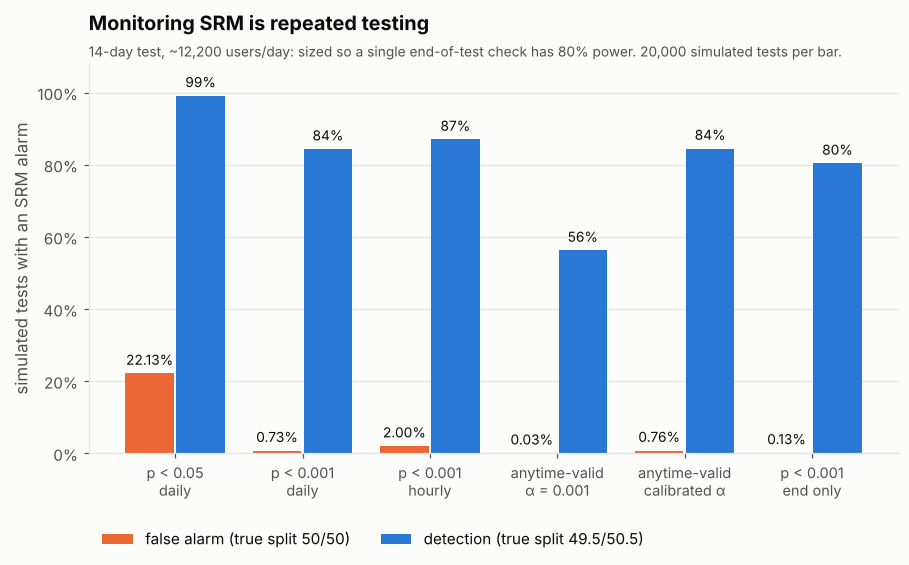

In [9]:
order = ["chi-square p<0.05, daily", "chi-square p<0.001, daily", "chi-square p<0.001, hourly",
         "mixture LR alpha=0.001, hourly", "mixture LR calibrated, hourly", "chi-square p<0.001, end only"]
labels = ["p < 0.05\ndaily", "p < 0.001\ndaily", "p < 0.001\nhourly", "anytime-valid\nα = 0.001",
          "anytime-valid\ncalibrated α", "p < 0.001\nend only"]
sub = srm_mon[srm_mon["daily_traffic"] == 12_192].set_index(["rule", "true_treatment_share"])
x, w = np.arange(len(order)), 0.38
fa = [sub.loc[(r, 0.5), "alarm_rate"] for r in order]
de = [sub.loc[(r, 0.495), "alarm_rate"] for r in order]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.bar(x - w / 2 - 0.01, fa, width=w, color=SERIES[1], label="false alarm (true split 50/50)")
ax.bar(x + w / 2 + 0.01, de, width=w, color=SERIES[0], label="detection (true split 49.5/50.5)")
for xi, v in zip(x - w / 2 - 0.01, fa):
    ax.text(xi, v + 0.015, f"{v:.2%}", ha="center", va="bottom", fontsize=9, color=TEXT)
for xi, v in zip(x + w / 2 + 0.01, de):
    ax.text(xi, v + 0.015, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=TEXT)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(pct)
ax.grid(axis="x", visible=False)
ax.set_ylabel("simulated tests with an SRM alarm")
ax.set_title("Monitoring SRM is repeated testing", pad=22)
ax.text(0, 1.01, "14-day test, ~12,200 users/day: sized so a single end-of-test check has 80% power. 20,000 simulated tests per bar.",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=9, color=TEXT_2)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16), ncol=2)
fig.savefig(FIGURES / "srm_monitoring.png")
plt.show()

The common default (α = 0.05, checked every morning) raises a false alarm on about one test in five. A strict threshold fixes most of it: 14 daily looks at p < 0.001 can't exceed 1.4% false alarms by a union bound. At equal nominal α the anytime-valid test looks weak, but most of that is Ville's slack. Calibrated to equal realized false alarms, it matches daily chi-square in power and detects slightly earlier because it can look hourly.

## 6. Validate the validator

The pipeline is a decision procedure too, so it has error rates: healthy experiments it blocks, broken ones it misses. Each scenario from section 2, rerun with fresh seeds. `N_SEEDS = 200` takes about 6 minutes; lower it for a quick look.

In [10]:
N_SEEDS = 200
rows = []
for seed in range(N_SEEDS):
    for name, _defect, expected, d, c in sim.defect_scenarios(seed=seed):
        r = validate_experiment(d, c)
        rows.append({"seed": seed, "scenario": name, "expected": expected,
                     "status": r.status.value, "reasons": "; ".join(r.reasons)})
runs = pd.DataFrame(rows)
summary = (runs.assign(correct=runs["status"] == runs["expected"])
               .groupby(["scenario", "expected"], sort=False)["correct"].mean()
               .rename("share_with_expected_status").reset_index())
summary.to_csv(RESULTS / "validate_the_validator.csv", index=False)
summary

,scenario,expected,share_with_expected_status
0,healthy,trustworthy,0.990
1,srm,untrustworthy,0.790
2,crossover,untrustworthy,1.000
3,exposure_loss_ios,untrustworthy,0.865
4,late_outcomes,preliminary,0.990
5,outcome_loss,untrustworthy,1.000
6,identity_split,untrustworthy,1.000
7,covariate_imbalance,untrustworthy,1.000


About 1% of healthy experiments get blocked: the price of running ~15 confirmatory tests per experiment at strict thresholds. The misses are power limits at 40,000 users: a one-point SRM (51/49) gives z ≈ 4.